In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

spam_emails = [
    "Congratulations you won a lottery",
    "Claim your free prize now",
    "You have won a cash reward",
    "Free gift waiting for you",
    "Congratulations claim your bonus",
    "Win a free vacation today",
    "You are selected for a prize",
    "Claim your lottery reward",
    "Get your free cash prize",
    "Special offer claim now",

    "Meeting at 10 AM tomorrow",
    "Project report submission is due",
    "Please attend the department meeting",
    "The class starts at 9 AM",
    "Submit the assignment by Friday",
    "Your project review is scheduled tomorrow",
    "Please send the meeting minutes",
    "The examination timetable is attached",
    "Faculty meeting is scheduled today",
    "Please complete the project report",
]

spam_labels = [
    "Spam"] * 10 + ["Not Spam"] * 10

spam_df = pd.DataFrame({
    "email": spam_emails,
    "label": spam_labels
})

spam_df


,email,label
0,Congratulations you won a lottery,Spam
1,Claim your free prize now,Spam
2,You have won a cash reward,Spam
3,Free gift waiting for you,Spam
4,Congratulations claim your bonus,Spam
5,Win a free vacation today,Spam
6,You are selected for a prize,Spam
7,Claim your lottery reward,Spam
8,Get your free cash prize,Spam
9,Special offer claim now,Spam


In [3]:

print("Dataset shape:", spam_df.shape)
print("\nClass distribution:")
print(spam_df["label"].value_counts())


Dataset shape: (20, 2)

Class distribution:
label
Spam        10
Not Spam    10
Name: count, dtype: int64


In [4]:

X_text = spam_df["email"]
y = spam_df["label"]

tfidf_spam = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2)
)

X_tfidf = tfidf_spam.fit_transform(X_text)

print("TF-IDF matrix shape:", X_tfidf.shape)
print("Vocabulary size:", len(tfidf_spam.vocabulary_))


TF-IDF matrix shape: (20, 79)
Vocabulary size: 79


In [5]:

feature_names = tfidf_spam.get_feature_names_out()

print("First 30 TF-IDF features:")
print(feature_names[:30])

tfidf_preview = pd.DataFrame(
    X_tfidf.toarray(),
    columns=feature_names
)

tfidf_preview.head()


First 30 TF-IDF features:
['10' '10 tomorrow' 'assignment' 'assignment friday' 'attached' 'attend'
 'attend department' 'bonus' 'cash' 'cash prize' 'cash reward' 'claim'
 'claim bonus' 'claim free' 'claim lottery' 'class' 'class starts'
 'complete' 'complete project' 'congratulations' 'congratulations claim'
 'congratulations won' 'department' 'department meeting' 'examination'
 'examination timetable' 'faculty' 'faculty meeting' 'free' 'free cash']


,10,10 tomorrow,assignment,assignment friday,attached,attend,attend department,bonus,cash,cash prize,...,today,tomorrow,vacation,vacation today,waiting,win,win free,won,won cash,won lottery
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.423014,0.000000,0.481236
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.423014,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.423014,0.481236,0.000000
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.469948,0.0,0.0,0.000000,0.000000,0.000000
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.482209,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000


In [6]:

X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])


Training samples: 15
Testing samples : 5


In [7]:

nb_model = MultinomialNB(alpha=1.0)
nb_model.fit(X_train, y_train)

print("Naïve Bayes model trained successfully.")


Naïve Bayes model trained successfully.


In [8]:

y_pred_nb = nb_model.predict(X_test)

results_nb = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_nb
})

results_nb


,Actual,Predicted
0,Not Spam,Spam
1,Not Spam,Spam
2,Spam,Spam
3,Spam,Spam
4,Not Spam,Spam


In [9]:

accuracy_nb = accuracy_score(y_test, y_pred_nb)

print(f"Naïve Bayes Accuracy: {accuracy_nb:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))


Naïve Bayes Accuracy: 40.00%

Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.00      0.00      0.00         3
        Spam       0.40      1.00      0.57         2

    accuracy                           0.40         5
   macro avg       0.20      0.50      0.29         5
weighted avg       0.16      0.40      0.23         5



C:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


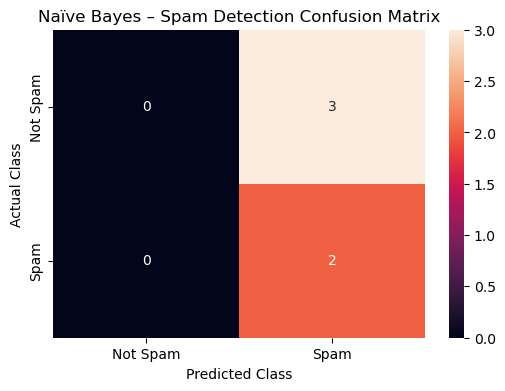

In [10]:

labels_nb = ["Not Spam", "Spam"]

cm_nb = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=labels_nb
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    xticklabels=labels_nb,
    yticklabels=labels_nb
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Naïve Bayes – Spam Detection Confusion Matrix")
plt.show()


In [11]:

reviews = [
    "This phone is excellent",
    "The camera quality is amazing",
    "I love this product",
    "The battery life is fantastic",
    "Very good performance and excellent design",
    "This is a wonderful phone",
    "The product works perfectly",
    "I am very happy with this purchase",
    "Excellent quality and great performance",
    "The phone is fast and reliable",

    "Battery performance is poor",
    "The camera quality is terrible",
    "I hate this product",
    "The phone is very slow",
    "Very bad performance",
    "The product stopped working",
    "I am unhappy with this purchase",
    "The quality is disappointing",
    "Poor battery and poor camera",
    "This phone is awful",

    "The product is okay",
    "The phone is average",
    "The camera is acceptable",
    "Battery performance is normal",
    "The product is neither good nor bad",
    "It works as expected",
    "The design is standard",
    "The performance is moderate",
    "The phone is fine",
    "The product is satisfactory"
]

sentiments = (
    ["Positive"] * 10 +
    ["Negative"] * 10 +
    ["Neutral"] * 10
)

review_df = pd.DataFrame({
    "review": reviews,
    "sentiment": sentiments
})

review_df


,review,sentiment
0,This phone is excellent,Positive
1,The camera quality is amazing,Positive
2,I love this product,Positive
3,The battery life is fantastic,Positive
4,Very good performance and excellent design,Positive
5,This is a wonderful phone,Positive
6,The product works perfectly,Positive
7,I am very happy with this purchase,Positive
8,Excellent quality and great performance,Positive
9,The phone is fast and reliable,Positive


In [12]:

new_emails = [
    "Congratulations you have won a free prize",
    "Please submit your project report tomorrow",
    "Claim your cash reward now",
    "The department meeting is at 10 AM"
]

new_email_tfidf = tfidf_spam.transform(new_emails)
new_predictions = nb_model.predict(new_email_tfidf)

new_email_results = pd.DataFrame({
    "New Email": new_emails,
    "Predicted Class": new_predictions
})

new_email_results


,New Email,Predicted Class
0,Congratulations you have won a free prize,Spam
1,Please submit your project report tomorrow,Not Spam
2,Claim your cash reward now,Spam
3,The department meeting is at 10 AM,Not Spam


In [13]:

reviews = [
    "This phone is excellent",
    "The camera quality is amazing",
    "I love this product",
    "The battery life is fantastic",
    "Very good performance and excellent design",
    "This is a wonderful phone",
    "The product works perfectly",
    "I am very happy with this purchase",
    "Excellent quality and great performance",
    "The phone is fast and reliable",

    "Battery performance is poor",
    "The camera quality is terrible",
    "I hate this product",
    "The phone is very slow",
    "Very bad performance",
    "The product stopped working",
    "I am unhappy with this purchase",
    "The quality is disappointing",
    "Poor battery and poor camera",
    "This phone is awful",

    "The product is okay",
    "The phone is average",
    "The camera is acceptable",
    "Battery performance is normal",
    "The product is neither good nor bad",
    "It works as expected",
    "The design is standard",
    "The performance is moderate",
    "The phone is fine",
    "The product is satisfactory"
]

sentiments = (
    ["Positive"] * 10 +
    ["Negative"] * 10 +
    ["Neutral"] * 10
)

review_df = pd.DataFrame({
    "review": reviews,
    "sentiment": sentiments
})

review_df


,review,sentiment
0,This phone is excellent,Positive
1,The camera quality is amazing,Positive
2,I love this product,Positive
3,The battery life is fantastic,Positive
4,Very good performance and excellent design,Positive
5,This is a wonderful phone,Positive
6,The product works perfectly,Positive
7,I am very happy with this purchase,Positive
8,Excellent quality and great performance,Positive
9,The phone is fast and reliable,Positive


In [14]:

print("Dataset shape:", review_df.shape)
print("\nSentiment distribution:")
print(review_df["sentiment"].value_counts())


Dataset shape: (30, 2)

Sentiment distribution:
sentiment
Positive    10
Negative    10
Neutral     10
Name: count, dtype: int64


In [15]:

X_review_text = review_df["review"]
y_review = review_df["sentiment"]

tfidf_review = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2)
)

X_review_tfidf = tfidf_review.fit_transform(X_review_text)

print("TF-IDF matrix shape:", X_review_tfidf.shape)
print("Vocabulary size:", len(tfidf_review.vocabulary_))


TF-IDF matrix shape: (30, 83)
Vocabulary size: 83


In [16]:

X_train_svm, X_test_svm, y_train_svm, y_test_svm = train_test_split(
    X_review_tfidf,
    y_review,
    test_size=0.30,
    random_state=42,
    stratify=y_review
)

print("Training samples:", X_train_svm.shape[0])
print("Testing samples :", X_test_svm.shape[0])


Training samples: 21
Testing samples : 9


In [17]:

svm_model = LinearSVC(C=1.0, random_state=42)
svm_model.fit(X_train_svm, y_train_svm)

print("SVM model trained successfully.")


SVM model trained successfully.


In [18]:

y_pred_svm = svm_model.predict(X_test_svm)

results_svm = pd.DataFrame({
    "Actual": y_test_svm.values,
    "Predicted": y_pred_svm
})

results_svm


,Actual,Predicted
0,Negative,Neutral
1,Positive,Neutral
2,Positive,Negative
3,Neutral,Neutral
4,Negative,Positive
5,Neutral,Negative
6,Positive,Neutral
7,Negative,Neutral
8,Neutral,Neutral


In [19]:

accuracy_svm = accuracy_score(y_test_svm, y_pred_svm)

print(f"SVM Accuracy: {accuracy_svm:.2%}")
print("\nClassification Report:")
print(classification_report(y_test_svm, y_pred_svm))


SVM Accuracy: 22.22%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         3
     Neutral       0.33      0.67      0.44         3
    Positive       0.00      0.00      0.00         3

    accuracy                           0.22         9
   macro avg       0.11      0.22      0.15         9
weighted avg       0.11      0.22      0.15         9



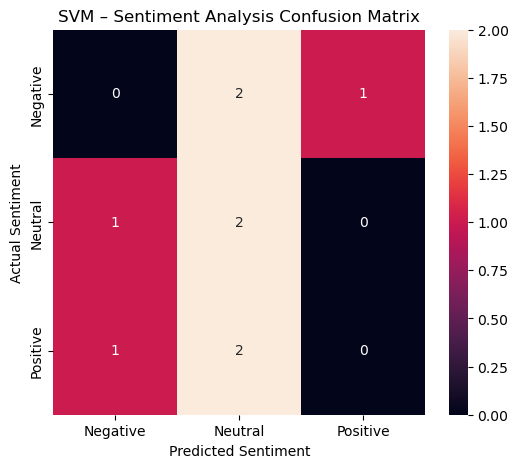

In [20]:

labels_svm = ["Negative", "Neutral", "Positive"]

cm_svm = confusion_matrix(
    y_test_svm,
    y_pred_svm,
    labels=labels_svm
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    xticklabels=labels_svm,
    yticklabels=labels_svm
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("SVM – Sentiment Analysis Confusion Matrix")
plt.show()


In [21]:

new_reviews = [
    "The phone has excellent performance",
    "The battery is very poor",
    "The product is average and acceptable",
    "I am extremely happy with the phone",
    "The camera quality is terrible"
]

new_review_tfidf = tfidf_review.transform(new_reviews)
new_predictions_svm = svm_model.predict(new_review_tfidf)

new_review_results = pd.DataFrame({
    "New Review": new_reviews,
    "Predicted Sentiment": new_predictions_svm
})

new_review_results


,New Review,Predicted Sentiment
0,The phone has excellent performance,Positive
1,The battery is very poor,Negative
2,The product is average and acceptable,Neutral
3,I am extremely happy with the phone,Positive
4,The camera quality is terrible,Negative


In [22]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# Sample news dataset
data = {
    "text": [
        "The cricket team won the match by five wickets",
        "The government announced new economic policies",
        "The company launched a new artificial intelligence product",
        "The stock market increased after strong company results",
        "The actor won an award for the best performance",
        "The football team qualified for the final",
        "Parliament passed a new education bill",
        "New smartphone technology was introduced by the company",
        "Investors are expecting higher profits this year",
        "The movie received excellent reviews from critics"
    ],

    "category": [
        "Sports",
        "Politics",
        "Technology",
        "Business",
        "Entertainment",
        "Sports",
        "Politics",
        "Technology",
        "Business",
        "Entertainment"
    ]
}

df = pd.DataFrame(data)

# Separate input and output
X = df["text"]
y = df["category"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Convert text into TF-IDF features
vectorizer = TfidfVectorizer(stop_words="english")
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Train Naive Bayes classifier
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

# Predict test data
y_pred = model.predict(X_test_tfidf)

# Evaluate model
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Classify a new news article
new_article = [
    "The team won the football championship after an exciting final"
]

new_article_tfidf = vectorizer.transform(new_article)
prediction = model.predict(new_article_tfidf)

print("Predicted Category:", prediction[0])

Accuracy: 0.0

Classification Report:
               precision    recall  f1-score   support

     Business       0.00      0.00      0.00       1.0
Entertainment       0.00      0.00      0.00       0.0
     Politics       0.00      0.00      0.00       1.0
       Sports       0.00      0.00      0.00       1.0
   Technology       0.00      0.00      0.00       0.0

     accuracy                           0.00       3.0
    macro avg       0.00      0.00      0.00       3.0
 weighted avg       0.00      0.00      0.00       3.0

Predicted Category: Entertainment
